# Step 4 – Cloude–Pottier decomposition (H / A / α)

For every selected scene:
1. Pauli vector $\mathbf{k} = \tfrac{1}{\sqrt{2}}[S_{HH}+S_{VV},\; S_{HH}-S_{VV},\; 2S_{HV}]^T$ (with $S_{HV} = (S_{HV}+S_{VH})/2$, reciprocity)
2. Coherency matrix $\mathbf{T} = \langle \mathbf{k}\mathbf{k}^H \rangle$, averaged over a window (multilook)
3. Eigenvalues $\lambda_1 \ge \lambda_2 \ge \lambda_3$ and eigenvectors $\mathbf{e}_i$ of $\mathbf{T}$, with $p_i = \lambda_i / \sum_j \lambda_j$

| Map | Formula | Meaning |
|---|---|---|
| span | $\sum_i \lambda_i$ | total backscattered power |
| entropy H | $-\sum_i p_i \log_3 p_i$ | 0 = one dominant mechanism, 1 = fully random |
| anisotropy A | $(\lambda_2-\lambda_3)/(\lambda_2+\lambda_3)$ | relation between the 2nd and 3rd mechanism; only meaningful when H is not low, so shown in grey where H < 0.3 |
| mean alpha α | $\sum_i p_i \arccos\lvert e_{1i}\rvert$ | 0–30° surface, 30–60° volume, 60–90° dihedral |
| mean beta β | $\sum_i p_i \arctan(\lvert e_{3i}\rvert / \lvert e_{2i}\rvert)$ | how the non-surface part is split between HH−VV (β ≈ 0°) and HV (β ≈ 90°) |
| beta β₁ | $\arctan(\lvert e_{31}\rvert / \lvert e_{21}\rvert)$ | the same for the dominant mechanism only (easier to interpret) |

The eigenvectors are written as $\mathbf{e} = [\cos\alpha,\ \sin\alpha\cos\beta\, e^{i\delta},\ \sin\alpha\sin\beta\, e^{i\gamma}]^T$: α gives the *type* of scattering, β how the non-surface part is distributed.

How to read β:
- For a single elongated scatterer tilted by an angle θ around the line of sight, β ≈ 2θ: β is then an *orientation*.
- In ice, much of the non-surface scattering is volume scattering, which appears in HV and pulls β towards 90° whatever the tilt. High β therefore often means "volume / depolarisation" rather than "tilted".
- β uses magnitudes, so it lies between 0° and 90° and does not show the *direction* of a tilt. The signed orientation angle of step 6 does, and is the better measure of tilt.
- β is undefined for pure surface scattering ($\sin\alpha \approx 0$); it is shown in grey where α < 15°.
- Over ice with HH ≈ VV, β is mostly saturated at ~90°. The β maps are therefore off by default (`SHOW_BETA = False`); β and β₁ are always saved in the GeoTIFF.

Before the decomposition, polarimetric checks are printed (HV ≈ VH and HH–VV phase ≈ 0° for calibrated data) together with the number of looks (H is biased low with fewer than ~30 looks).

Results per scene: `<product>_h_alpha.png`, and a 6-band `.tif` (span, H, A, α, β, β₁).
**Output folders**: every run gets its own folder with a time stamp, so earlier results are never overwritten. Inside it, the folders mirror the input folders, so every result can be traced back to its product:
`<OUTPUT_DIR>/<date_time>_<analysis>[_<label>]/<stack folder>/L1C/<product>/<product>_<analysis>.png` (and `.tif`).
Each run folder has a `run_info.json` (settings and scenes of the run), and each stack folder a `stack_info.json` (stack ID, primary, what has been processed).

**How to use**
0. First time only: run **4.0** to install the packages, then restart the kernel.
1. Set `DATA_DIR` and `OUTPUT_DIR` in **4.1**, then run **4.1** and **4.2**: they load the tools and list all stacks (with their stack ID) and scenes (★ = primary).
2. Fill in **4.3 Settings**: which stacks and scenes to process.
3. Run **4.4**.

`BiomassProduct.py` (ESA) and `polsar_utils.py` must be in the same folder as this notebook.

## 4.0 First time only: install the packages
Run once, then restart the kernel (**Kernel → Restart Kernel**). `--user` installs them in your home folder, so they are kept when the server restarts. Skip this cell if 4.1 runs without errors.

In [1]:
%pip install --user netCDF4 xarray folium shapely pillow

Note: you may need to restart the kernel to use updated packages.


## 4.1 Load the tools and choose the folders
- `DATA_DIR`: the folder that contains your stacks. It can be a folder on your computer or a cloud bucket mounted as a folder. Leave it as `None` to search automatically.
- `OUTPUT_DIR`: the main folder for all results. It is created if it does not exist; `~` is your home folder.

In [20]:
%matplotlib inline
import polsar_utils as pu

DATA_DIR = "/home/jovyan/shared-buckets/6e08893c-463e-498b-92d2-6761dd17160d/biomass_inputs"  # e.g. "/path/to/biomass_inputs"; None = search automatically
OUTPUT_DIR = "/home/jovyan/idas_dump/test/Nivlisen"  # main folder for all result

## 4.2 Overview of the data

In [21]:
stacks = pu.find_stacks(DATA_DIR)
pu.print_overview(stacks)

8 stack(s), 55 scene(s)

[0] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS  (6 scenes)
      [0] 2026-07-04 16:11             BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC
      [1] 2026-07-07 16:11             BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
      [2] 2026-07-10 16:11             BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
      [3] 2026-07-13 16:11  ★ primary  BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
      [4] 2026-07-19 16:11             BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
      [5] 2026-07-22 16:11             BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N
[1] BIO_S1_STA__ID_20260915T214352_20261003T214425_T_G01_M05_S0720_W0730_D_02_DZ1NQJ  (7 scenes)
      [0] 2026-09-15 21:43             BIO_S1_STA__1S_2026091

## 4.3 Settings
**Which data**
- `STACKS`: `"all"`, stack names such as `["stack_01", "stack_20"]`, stack IDs (the full ID or just its end, e.g. `["DZ1NQJ"]`), or numbers from the list in 4.2 such as `[0, 2]`
- `SCENES`: `"all"`, `"primary"` (only the primary of each stack), dates such as `["2026-09-15"]`, or numbers within each stack such as `[0, 3]`

Numbers start at 0, as in the list in 4.2.

**Where the results go** (inside `OUTPUT_DIR` from 4.1)
- `NEW_RUN_FOLDER`: `True` = a new folder with a time stamp for every run (nothing is overwritten); `False` = write directly in `OUTPUT_DIR`
- `RUN_LABEL`: optional name added to the run folder, e.g. `"window200"`
- `SKIP_EXISTING`: only used when `NEW_RUN_FOLDER = False`: skip scenes that already have a result there (and show the saved result)

**Processing**
- `WINDOW_M`: averaging window in metres for the coherency matrix (100 m gives ~50 looks with BIOMASS)
- `SHOW_BETA`: also show the two β maps
- `SAVE_GEOTIFF`: also save a GeoTIFF

In [22]:
STACKS = ["DV87RS"]
SCENES = "all"

NEW_RUN_FOLDER = True
RUN_LABEL = "window100"
WINDOW_M = 100
SHOW_BETA = False
SAVE_GEOTIFF = True
SKIP_EXISTING = True
SHOW_FIGURES = True

## 4.4 Run

Selected 6 scene(s) in 1 stack(s):
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-04 16:11 | BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-07 16:11 | BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-10 16:11 | BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-13 16:11  ★ primary | BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
   BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-19 16:11 | BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
   BIO_S1_STA__ID_202607

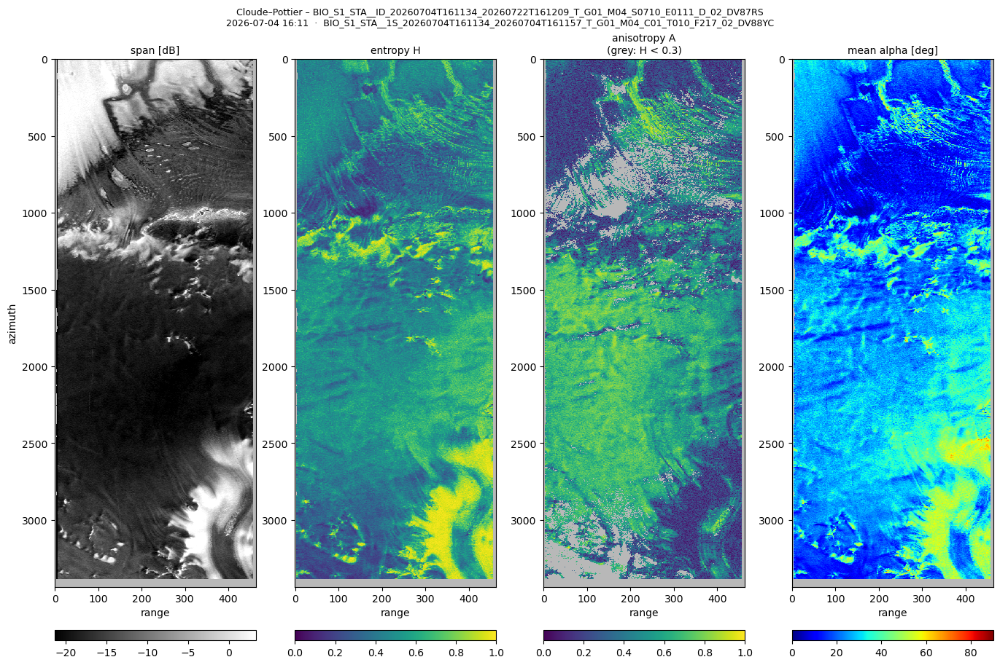

  saved BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC_h_alpha.png
  saved BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC_h_alpha.tif

[2/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-07 16:11 | BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  checks: |corr(HV,VH)| 0.97, HV/VH -0.01 dB, HH-VV phase +20.7°, |corr(HH,VV)| 0.64
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  mean H 0.51, A 0.46, alpha 26.3°, beta 26.8° (78% of pixels with alpha ≥ 15°)


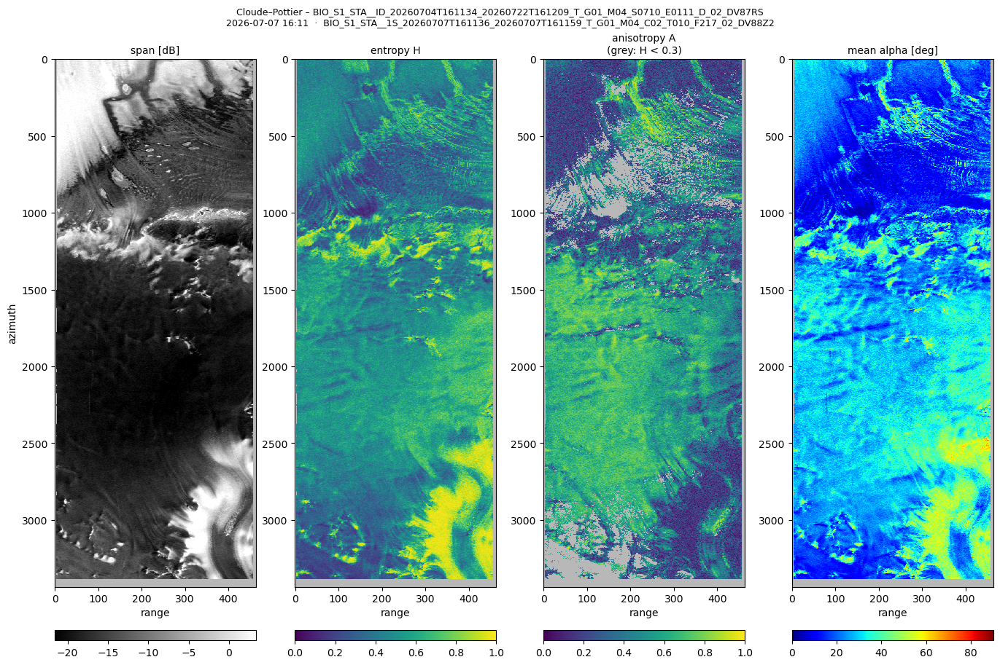

  saved BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2_h_alpha.png
  saved BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2_h_alpha.tif

[3/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-10 16:11 | BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  checks: |corr(HV,VH)| 0.97, HV/VH -0.01 dB, HH-VV phase +20.9°, |corr(HH,VV)| 0.64
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  mean H 0.51, A 0.46, alpha 26.4°, beta 26.8° (79% of pixels with alpha ≥ 15°)


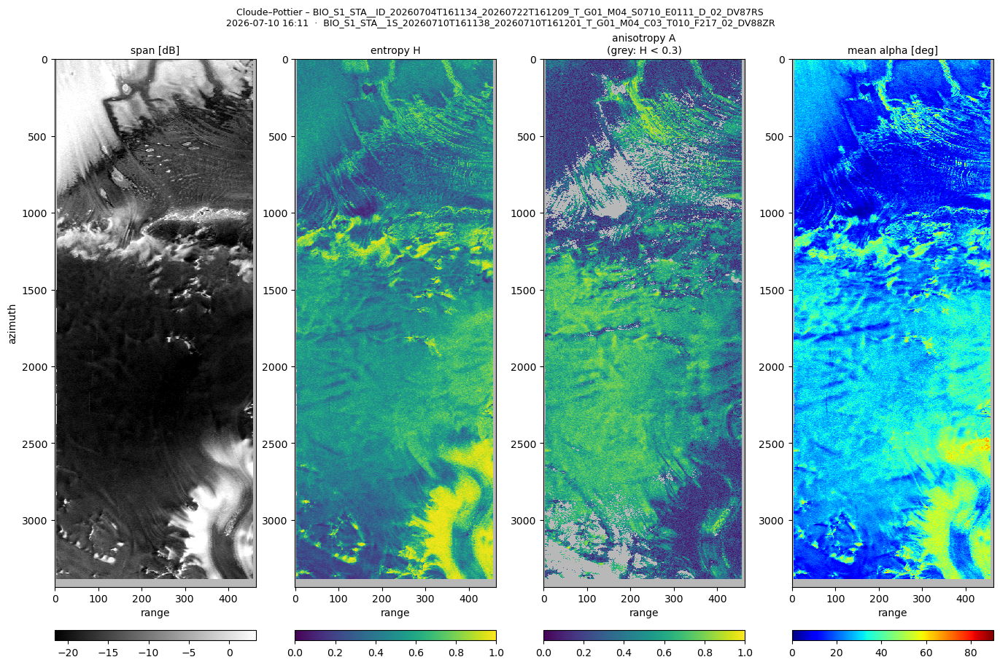

  saved BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR_h_alpha.png
  saved BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR_h_alpha.tif

[4/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-13 16:11  ★ primary | BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  checks: |corr(HV,VH)| 0.97, HV/VH -0.00 dB, HH-VV phase +20.9°, |corr(HH,VV)| 0.64
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  mean H 0.51, A 0.46, alpha 26.2°, beta 27.1° (79% of pixels with alpha ≥ 15°)


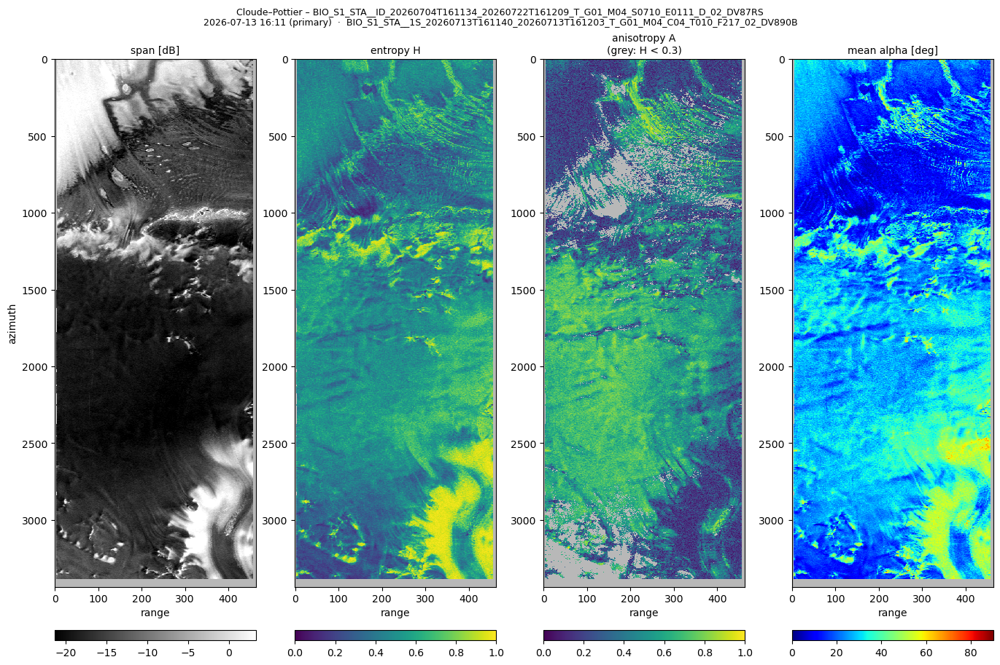

  saved BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B_h_alpha.png
  saved BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B_h_alpha.tif

[5/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-19 16:11 | BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
  image 24039 x 928 (azimuth x range), valid pixels 95.5%, phase stored in radians
  checks: |corr(HV,VH)| 0.97, HV/VH -0.01 dB, HH-VV phase +21.0°, |corr(HH,VV)| 0.64
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  mean H 0.49, A 0.47, alpha 24.4°, beta 27.1° (78% of pixels with alpha ≥ 15°)


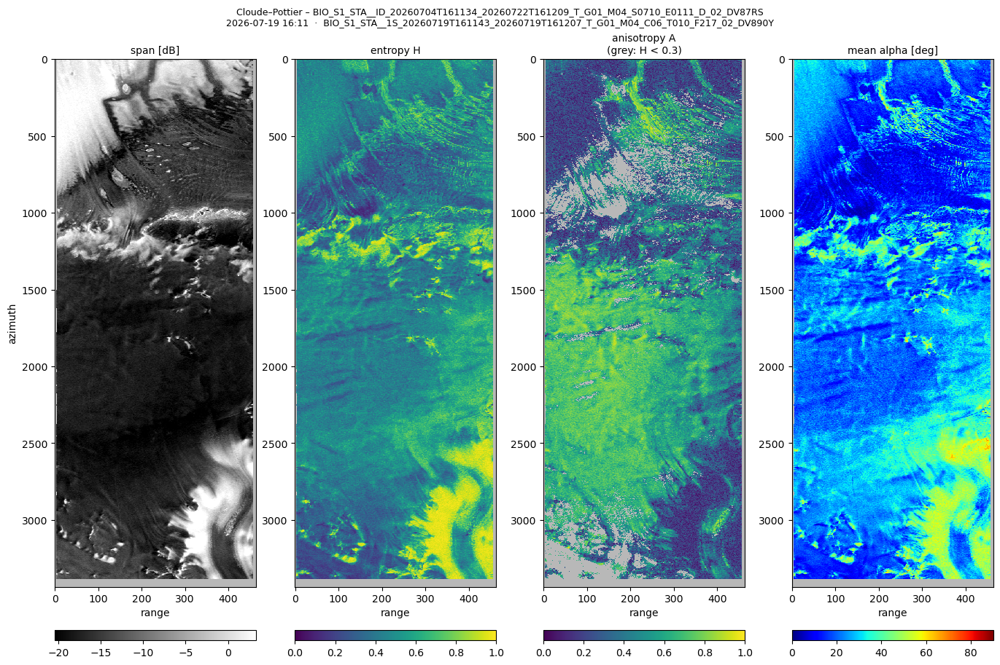

  saved BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y_h_alpha.png
  saved BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y_h_alpha.tif

[6/6] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS | 2026-07-22 16:11 | BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N
  image 24039 x 928 (azimuth x range), valid pixels 95.4%, phase stored in radians
  checks: |corr(HV,VH)| 0.97, HV/VH -0.01 dB, HH-VV phase +21.0°, |corr(HH,VV)| 0.64
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  mean H 0.49, A 0.48, alpha 24.5°, beta 27.3° (77% of pixels with alpha ≥ 15°)


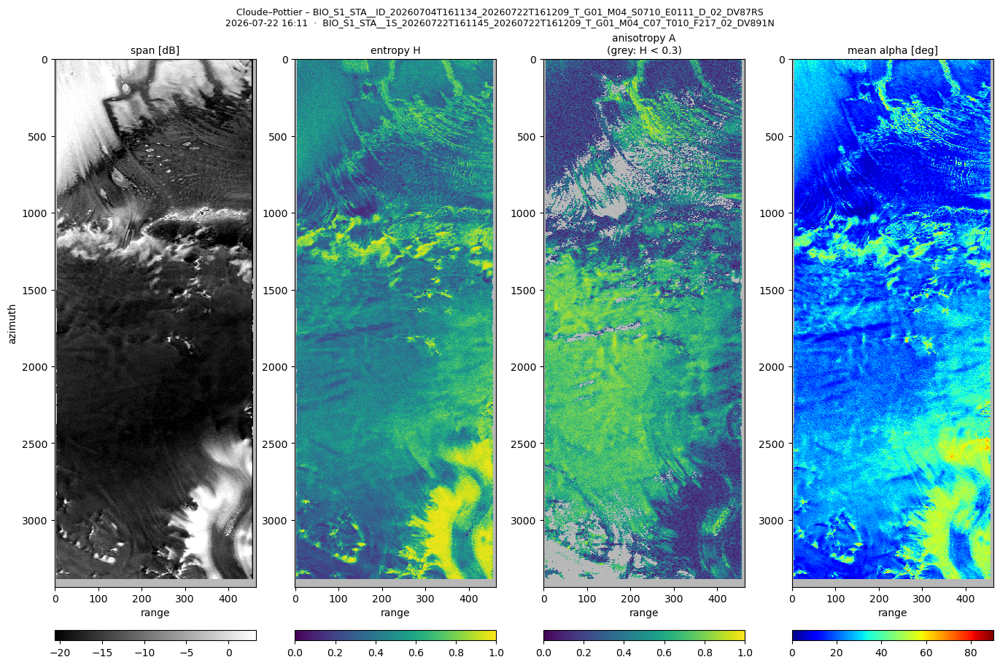

  saved BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N_h_alpha.png
  saved BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N_h_alpha.tif

Finished: 6 processed, 0 already done, 0 failed. Results in /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_133848_h_alpha_window100


[]

In [23]:
scenes = pu.select_scenes(stacks, STACKS, SCENES)
run_dir = pu.new_run_folder(OUTPUT_DIR, "h_alpha", NEW_RUN_FOLDER, RUN_LABEL,
                            settings=dict(window_m=WINDOW_M, show_beta=SHOW_BETA, geotiff=SAVE_GEOTIFF, stacks=STACKS, scenes=SCENES), scenes=scenes)
pu.run_cloude_pottier(scenes, run_dir, window_m=WINDOW_M, geotiff=SAVE_GEOTIFF,
                      skip_existing=SKIP_EXISTING, show=SHOW_FIGURES, show_beta=SHOW_BETA)

## 4.5 Extra: find the primary of each stack
The primary is the coregistration reference of the stack (`isCoregistrationPrimary` in the product XML).
`PRIMARY_STACKS`: `"all"`, stack names such as `["stack_01"]`, or numbers such as `[0, 2]`.

In [ ]:
PRIMARY_STACKS = "all"

primaries = pu.print_primaries(stacks, PRIMARY_STACKS)